# NB1 — Baseline: variance propagation and the α = 1/√2 control

**Purpose.**
1. Reproduce the textbook claims this project builds on: with He initialisation a residual
   block doubles the activation variance (UDL §11.3), and rescaling by 1/√2 keeps it
   constant (UDL Fig. 11.6b).
2. Derive and check the initialisation σ²(α) = 2(1−α²)/D, and the per-block calibration that
   holds the forward variance fixed for any skip weight α, including a check of the backward pass.
3. Train the control condition used in NB2 (32 blocks, α = 1/√2) with ≥ 3 seeds and analyse
   its variability.

**Contents.** 0 Setup · 1 Model · 2 Reproducing variance doubling · 3 Derivation of σ²(α) ·
4 Finite-width spread and calibration · 5 Training the baseline · 6 Variability ·
7 Decisions carried into NB2

In [11]:
QUICK = False  # Submission target: cached runs in under five minutes on the lab kernel.

## 0. Setup

In [2]:
import time
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

import config as C
from utils import (env_report, get_device, set_seed, make_generator, load_fashion_mnist,
                   iterate_minibatches, evaluate, save_result, result_exists, load_results,
                   summarise, plot_mean_sd, plot_seed_points)

T0 = time.time()
ENV = env_report()
DEVICE = get_device()
DATA = load_fashion_mnist(device=DEVICE, n_val=C.N_VAL, split_seed=C.SPLIT_SEED,
                          n_calib=C.N_CALIB, calib_seed=C.CALIB_SEED)
print({k: tuple(v.shape) for k, v in DATA.items() if torch.is_tensor(v)})

         python: 3.9.6
       platform: macOS-27.2.1-arm64-arm-64bit
          torch: 2.8.0
          numpy: 2.0.2
 cuda_available: False
  mps_available: True
         device: mps
    torchvision: 0.23.0
     matplotlib: 3.9.4
{'x_train': (50000, 784), 'y_train': (50000,), 'x_val': (10000, 784), 'y_val': (10000,), 'x_test': (10000, 784), 'y_test': (10000,), 'x_calib': (512, 784)}


## 1. Model

Pre-activation residual block (UDL Fig. 11.5b): `h ← α·h + W·ReLU(h)`, no bias and no
normalisation, as specified in the design.

_TODO (owner): explain in a few sentences why the activation comes before the linear layer,
and why bias and normalisation are left out._

In [3]:
class ResMLP(nn.Module):
    """Pre-activation residual MLP.

    input  : Linear(784 -> D, bias=False)                  -> h_0
    block l: h_{l+1} = alpha * h_l + W_l(ReLU(h_l))         W_l = Linear(D -> D, bias=False)
    output : Linear(D -> 10, bias=False) applied to h_L      (logits)

    forward(x, return_hidden=False) -> logits, or (logits, [h_0, ..., h_L]) if return_hidden.
    """

    def __init__(self, depth: int, width: int = C.WIDTH, alpha: float = 0.0):
        super().__init__()
        self.alpha = alpha
        self.input_layer = nn.Linear(C.IN_DIM, width, bias=False)
        self.blocks = nn.ModuleList(
            nn.Linear(width, width, bias=False) for _ in range(depth)
        )
        self.output_layer = nn.Linear(width, C.N_CLASSES, bias=False)

    def forward(self, x: torch.Tensor, return_hidden: bool = False):
        x = x.flatten(start_dim=1)
        h = self.input_layer(x)

        if return_hidden:
            hidden = [h]

        for block in self.blocks:
            h = self.alpha * h + block(torch.relu(h))
            if return_hidden:
                hidden.append(h)

        logits = self.output_layer(h)
        if return_hidden:
            return logits, hidden
        return logits

In [4]:
@torch.no_grad()
def init_weights(model: ResMLP, alpha: float, sigma2_block: "float | None" = None) -> None:
    """Initialise all weights in place with zero-mean Gaussians.

    input layer: N(0, 1/784); every block: N(0, sigma2_block), default 2(1 - alpha^2)/D;
    output layer: N(0, 1/D). Pass sigma2_block = 2/D for plain He initialisation (Section 2).

    Where the three variances come from
    -----------------------------------
    A linear layer with `n_in` inputs keeps the second moment of its output equal to that of its
    input when the weights have variance 1/n_in (the usual He rule for a bias-free linear map).
    The input layer therefore uses 1/784 on standardised pixels, so E[h_0^2] = 1.

    Inside a block the skip term adds the variance alpha^2 and the branch adds (1/2) * D * sigma^2
    (Section 3), so holding the block at ratio 1 asks for sigma^2 = 2 (1 - alpha^2) / D. With
    alpha = 0 this is the plain He value 2/D, and with alpha = 1/sqrt(2) it is 1/D, the UDL
    Fig. 11.6b rescaling.

    The output layer uses 1/D, so the logits start at the same scale as the last hidden layer for
    every alpha. That keeps the initial output scale comparable between conditions; it is not
    used by the variance argument itself.
    """
    depth_width = model.input_layer.out_features          # D
    if sigma2_block is None:
        sigma2_block = 2.0 * (1.0 - alpha ** 2) / depth_width
    if sigma2_block < 0.0:
        raise ValueError(f"alpha = {alpha} gives a negative block variance; need |alpha| <= 1")

    model.input_layer.weight.normal_(mean=0.0, std=model.input_layer.in_features ** -0.5)
    for block in model.blocks:
        block.weight.normal_(mean=0.0, std=float(sigma2_block) ** 0.5)
    model.output_layer.weight.normal_(mean=0.0, std=depth_width ** -0.5)

## 2. Reproducing UDL §11.3: variance doubling and the 1/√2 fix

Forward pass only, no training. For ≥ 10 networks (different seeds), push `DATA["x_calib"]`
through the network and record E[h_l²] / E[h_0²] for every layer l:

- (a) α = 1 with He initialisation (σ² = 2/D): expected to grow by ≈ ×2 per block;
- (b) α = 1/√2 with σ² = 1/D: expected to stay ≈ 1.

Plot mean ± sd over networks against l (log scale for (a)). Report the per-block factor as an
average over networks: a single network deviates because of finite width (Section 4).

(a) alpha = 1, He:        per-block factor 1.997 +/- 0.030   (theory 2.000)
    final layer, 12 networks: median 4.08e+09  range 1.9e+09...9.47e+09  (5.0x)  mean 4.51e+09 +/- 2.21e+09
(b) alpha = 1/sqrt(2):    per-block factor 0.998 +/- 0.015   (theory 1.000)
    final layer, 12 networks: median 0.951  range 0.442...2.2  (5.0x)  mean 1.05 +/- 0.515


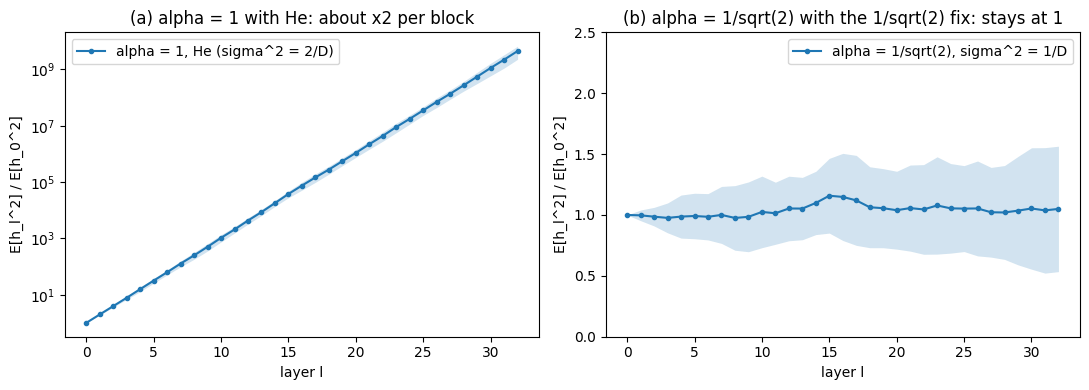

In [5]:
N_NETWORKS = 12       # the protocol asks for >= 10 networks
BASE_SEED = 100       # seeds 100...111: they only make the check reproducible, they are not run seeds


def relative_second_moments(model: "ResMLP", x: torch.Tensor) -> np.ndarray:
    """E[h_l^2] / E[h_0^2] for l = 0...L, on one fixed batch and with no gradients."""
    model.eval()
    with torch.no_grad():
        _, hidden = model(x, return_hidden=True)
        m2 = torch.stack([h.pow(2).mean() for h in hidden])
    return (m2 / m2[0]).cpu().numpy()


def variance_propagation(depth: int, alpha: float, sigma2_block: float, x: torch.Tensor,
                         n_networks: int = N_NETWORKS, base_seed: int = BASE_SEED):
    """One curve per network, plus the per-block factor of each network.

    The per-block factor is the geometric mean, (final ratio) ** (1 / depth). Averaged over
    networks it should be the multiplier the derivation predicts; single networks deviate because
    the width is finite (Section 4).
    """
    curves, factors = [], []
    for i in range(n_networks):
        set_seed(base_seed + i)
        model = ResMLP(depth, C.WIDTH, alpha).to(x.device)
        init_weights(model, alpha, sigma2_block=sigma2_block)
        curve = relative_second_moments(model, x)
        curves.append(curve)
        factors.append(curve[-1] ** (1.0 / depth))
    return np.stack(curves), np.array(factors)


def describe(values: np.ndarray) -> str:
    """Multiplicative spread: median and the min...max range, plus mean +- sd."""
    values = np.asarray(values, dtype=float)
    return (f"median {np.median(values):.3g}  range {values.min():.3g}...{values.max():.3g}  "
            f"({values.max() / values.min():.1f}x)  mean {values.mean():.3g} +/- {values.std(ddof=1):.3g}")


# (a) alpha = 1 with plain He (sigma^2 = 2/D): the textbook doubling
curves_he, factor_he = variance_propagation(C.DEPTH_MAIN, 1.0, 2.0 / C.WIDTH, DATA["x_calib"])
# (b) alpha = 1/sqrt(2) with sigma^2 = 1/D: the same sigma^2(alpha), i.e. He * 1/sqrt(2)
curves_fix, factor_fix = variance_propagation(C.DEPTH_MAIN, C.ALPHA_UDL, 1.0 / C.WIDTH, DATA["x_calib"])

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
layers = np.arange(curves_he.shape[1])
plot_mean_sd(axes[0], layers, curves_he, label="alpha = 1, He (sigma^2 = 2/D)", marker="o", ms=3)
plot_mean_sd(axes[1], layers, curves_fix, label="alpha = 1/sqrt(2), sigma^2 = 1/D", marker="o", ms=3)
axes[0].set_yscale("log")
axes[0].set_title("(a) alpha = 1 with He: about x2 per block")
axes[1].set_title("(b) alpha = 1/sqrt(2) with the 1/sqrt(2) fix: stays at 1")
axes[1].set_ylim(0.0, 2.5)
for ax in axes:
    ax.set_xlabel("layer l")
    ax.set_ylabel("E[h_l^2] / E[h_0^2]")
    ax.legend()

print(f"(a) alpha = 1, He:        per-block factor {factor_he.mean():.3f} +/- {factor_he.std(ddof=1):.3f}"
      f"   (theory 2.000)")
print(f"    final layer, {N_NETWORKS} networks: {describe(curves_he[:, -1])}")
print(f"(b) alpha = 1/sqrt(2):    per-block factor {factor_fix.mean():.3f} +/- {factor_fix.std(ddof=1):.3f}"
      f"   (theory 1.000)")
print(f"    final layer, {N_NETWORKS} networks: {describe(curves_fix[:, -1])}")
plt.tight_layout();

## 3. Deriving σ²(α)

The block is $h_{l+1} = \alpha h_l + W_l\,\mathrm{ReLU}(h_l)$ with $W_l \in \mathbb{R}^{D \times D}$,
entries i.i.d. $\mathcal N(0,\sigma^2)$, no bias. Write $q_l = \mathbb E[h_l^2]$, averaged over the
$D$ units and over the batch. Assume the units are exchangeable and $h_l$ is centred, so ReLU
keeps half of the second moment: $\mathbb E[\mathrm{ReLU}(h)^2] = \tfrac12\, q_l$.

### Forward

For one output unit $i$ the branch is $\sum_j W_{ij}\,\mathrm{ReLU}(h_j)$, so its second moment is

$$\mathbb E\Big[\big(\textstyle\sum_j W_{ij}\mathrm{ReLU}(h_j)\big)^2\Big]
 = \sum_j \sigma^2\,\mathbb E[\mathrm{ReLU}(h_j)^2]
 = \sigma^2 D \cdot \tfrac12 q_l .$$

The cross term vanishes, $\mathbb E[h\cdot W\,\mathrm{ReLU}(h)] = 0$, because $W_l$ is zero-mean and
independent of $h_l$ ($h_l$ is built from $W_{<l}$ only). So

$$q_{l+1} = \alpha^2 q_l + \tfrac12 D\sigma^2 q_l
 \quad\Longrightarrow\quad \frac{q_{l+1}}{q_l} = \alpha^2 + \tfrac12 D\sigma^2 .$$

Setting the ratio to 1 gives the initialisation the design uses:

$$\boxed{\ \sigma^2(\alpha) = \frac{2(1-\alpha^2)}{D}\ }$$

### Backward

The gradient with respect to $h_l$ is
$\delta_l = \alpha\,\delta_{l+1} + \mathrm{diag}(\mathbb 1[h_l>0])\,W_l^\top \delta_{l+1}$,
with $\delta_L = \partial \mathcal L/\partial h_L$. Write $s_l = \mathbb E[\delta_l^2]$ per unit.

The branch part of one unit $j$ is $\mathbb 1[h_j>0]\sum_i W_{ij}\delta_{l+1,i}$, hence

$$\mathbb E\big[\text{branch}_j^2\big]
 = \mathbb 1[h_j>0]\,\sigma^2 \sum_i \mathbb E[\delta_{l+1,i}^2]
 = \mathbb 1[h_j>0]\,\sigma^2 D\, s_{l+1},$$

and averaging the indicator over units gives a factor $\tfrac12$. The cross term is zero for the
same reason as in the forward pass: $\delta_{l+1}$ depends on $W_{l+1},\dots$ but not on $W_l$, and
$\mathbb E[W_{ij}] = 0$. Therefore

$$s_l = \big(\alpha^2 + \tfrac12 D\sigma^2\big)\, s_{l+1},$$

exactly the same factor as the forward pass. This is why one initialisation fixes both directions,
and why no separate backward rescaling is needed. It is also why $W$ being square ($D\to D$)
matters here: the sum over $i$ runs over $D$ terms in both directions.

### Special cases

| $\alpha$ | $\sigma^2(\alpha)$ | per-block ratio $\alpha^2 + \tfrac12 D\sigma^2$ | what it is |
|---|---|---|---|
| $0$ | $2/D$ | $1$ | plain deep net with He initialisation (BL5) |
| $1/\sqrt2$ | $1/D$ | $1$ | He $\times\,1/\sqrt2$, the UDL Fig. 11.6b rescaling |
| $1$ with He | $2/D$ | $2$ | the variance doubling of UDL §11.3 |

Two remarks we need later.

- The derivation is in expectation over the weights. A single finite-width network misses the
  ratio by a random amount, and those errors multiply over 32 blocks (Section 4). That is what
  the calibration step is for.
- The result only holds because the block is pre-activation — ReLU first, then the linear map —
  as in UDL Fig. 11.5b. It is also why the model has no bias and no normalisation: a bias would
  break the zero-mean assumption, and normalisation would set the variance by force instead of by
  the initialisation we are testing.

## 4. Finite-width spread and calibration

The derivation holds in expectation over the weights. Show how much single networks deviate
(final-layer variance across ≥ 10 networks, for each α in `C.ALPHAS[32]`), then calibrate each
network so its forward variance is exactly preserved on the calibration batch.

Checks to report for every condition (both depths):
1. forward: per-layer E[h_l²] ratio after calibration = 1.000 (and close to 1 on held-out data);
2. backward: per-layer second moment of ∂loss/∂h_l compared across conditions
   (hint: `h.retain_grad()` on the hidden states returned by `forward(..., return_hidden=True)`).

In [6]:
@torch.no_grad()
def calibrate(model: ResMLP, x_calib: torch.Tensor, alpha: float) -> list[float]:
    """Rescale each block's W so that E[h_{l+1}^2] = E[h_l^2] exactly on x_calib.

    For block l with f = W_l(ReLU(h_l)):  a = E[f^2], b = E[h_l * f], c = E[h_l^2]
        s = (-alpha * b + sqrt(alpha^2 * b^2 + (1 - alpha^2) * a * c)) / a,   W_l <- s * W_l
    Process the blocks in order, so block l+1 sees the already-calibrated h_{l+1}.
    Returns the list of scale factors s (they should all be close to 1).

    The formula is the positive root of alpha^2 c + 2 alpha s b + s^2 a = c, i.e. of
    E[(alpha h + s f)^2] = E[h^2]. It is the LSUV idea with the skip term kept: we do not want a
    block-wise unit variance, we want the *ratio* to stay 1 at this alpha.
    Only the forward pass is matched here, so the backward pass is checked separately (Section 4).
    """
    model.eval()
    h = model.input_layer(x_calib.flatten(start_dim=1))
    scales: list[float] = []

    for block in model.blocks:
        f = block(torch.relu(h))
        # reduce on the device, then finish the arithmetic in Python floats (double):
        # MPS has no float64, and the scalars are small so the cost is irrelevant.
        a = float(f.pow(2).mean())
        b = float((h * f).mean())
        c = float(h.pow(2).mean())
        if not (a > 0.0) or a != a:
            raise ValueError("the residual branch is zero (or not finite); nothing to rescale")

        root = ((alpha * b) ** 2 + (1.0 - alpha ** 2) * a * c) ** 0.5
        s = (-alpha * b + root) / a

        block.weight.mul_(s)
        h = alpha * h + s * f          # the next block must see the rescaled output
        scales.append(s)

    return scales

In [7]:
def final_layer_variance(model: "ResMLP", x: torch.Tensor) -> float:
    """E[h_L^2] on one batch (no gradients): the scale that reaches the output layer."""
    model.eval()
    with torch.no_grad():
        _, hidden = model(x, return_hidden=True)
        return float(hidden[-1].pow(2).mean())


def build(alpha: float, depth: int = C.DEPTH_MAIN, seed: int = BASE_SEED,
          calibrate_it: bool = True) -> "ResMLP":
    """A fresh network for one condition: seed -> init -> (optionally) calibrate."""
    set_seed(seed)
    model = ResMLP(depth, C.WIDTH, alpha).to(DATA["x_calib"].device)
    init_weights(model, alpha)
    if calibrate_it:
        calibrate(model, DATA["x_calib"], alpha)
    return model


def gradient_second_moments(model: "ResMLP", x: torch.Tensor, y: torch.Tensor):
    """E[(d loss / d h_l)^2] for l = 0...L, and the loss value, on one batch."""
    model.eval()
    model.zero_grad(set_to_none=True)
    logits, hidden = model(x, return_hidden=True)
    for h in hidden:
        h.retain_grad()
    loss = nn.functional.cross_entropy(logits, y)
    loss.backward()
    grads = torch.stack([h.grad.detach().pow(2).mean() for h in hidden]).cpu().numpy()
    loss_value = float(loss.detach())
    model.zero_grad(set_to_none=True)
    return grads, loss_value


x_bwd, y_bwd = DATA["x_train"][:512], DATA["y_train"][:512]   # a fixed batch for the backward check
rows = []
for alpha in C.ALPHAS[C.DEPTH_MAIN]:
    spread, dev_calib, held_final, bwd_factor, bwd_level = [], [], [], [], []
    for i in range(N_NETWORKS):
        seed = BASE_SEED + i

        raw = build(alpha, seed=seed, calibrate_it=False)          # before calibration
        spread.append(final_layer_variance(raw, DATA["x_calib"]))

        model = build(alpha, seed=seed)                            # after calibration
        cal = relative_second_moments(model, DATA["x_calib"])
        dev_calib.append(float(np.abs(cal - 1.0).max()))
        held_final.append(float(relative_second_moments(model, DATA["x_val"][:512])[-1]))

        grads, _ = gradient_second_moments(model, x_bwd, y_bwd)
        bwd_factor.append((grads[0] / grads[-1]) ** (1.0 / C.DEPTH_MAIN))
        bwd_level.append(grads[-1])

    spread = np.array(spread)
    rows.append({
        "alpha": alpha,
        "spread": spread.max() / spread.min(),      # how far single networks drift apart
        "dev_calib": float(np.max(dev_calib)),      # worst per-layer deviation from 1
        "held_final": float(np.mean(held_final)),   # forward ratio on data it never saw
        "bwd_factor": float(np.mean(bwd_factor)),
        "bwd_level": float(np.mean(bwd_level)),
    })

print(f"{'alpha':>6} | {'E[h_L^2] max/min':>16} | {'worst |ratio-1|':>15} | "
      f"{'held-out E[h_L^2]/E[h_0^2]':>26} | {'bwd per-block':>13} | {'E[dL/dh_L]^2':>12}")
print("-" * 100)
for r in rows:
    print(f"{r['alpha']:6.4f} | {r['spread']:16.2f} | {r['dev_calib']:15.2e} | "
          f"{r['held_final']:26.4f} | {r['bwd_factor']:13.4f} | {r['bwd_level']:12.2e}")

levels = np.array([r["bwd_level"] for r in rows])
print(f"\nacross the six conditions, E[(dL/dh_L)^2] spans {levels.min():.2e} ... {levels.max():.2e} "
      f"(largest/smallest = {levels.max() / levels.min():.2f})")

 alpha | E[h_L^2] max/min | worst |ratio-1| | held-out E[h_L^2]/E[h_0^2] | bwd per-block | E[dL/dh_L]^2
----------------------------------------------------------------------------------------------------
0.0000 |             4.89 |        1.07e-06 |                     1.0002 |        1.0125 |     1.48e-08
0.5000 |             5.15 |        4.77e-07 |                     0.9891 |        1.0069 |     1.44e-08
0.7071 |             5.09 |        7.75e-07 |                     0.9993 |        1.0013 |     1.45e-08
0.7906 |             4.88 |        8.34e-07 |                     1.0061 |        1.0030 |     1.47e-08
0.9000 |             3.39 |        1.37e-06 |                     1.0061 |        1.0024 |     1.47e-08
0.9700 |             1.54 |        1.91e-06 |                     1.0036 |        1.0031 |     1.46e-08

across the six conditions, E[(dL/dh_L)^2] spans 1.44e-08 ... 1.48e-08 (largest/smallest = 1.03)



### What the checks showed (local run, to be repeated on the lab machine)

These numbers come from one local run on Apple MPS (torch 2.15, 12 networks per condition, seeds
100–111, the 512 calibration images). They are a sanity check for the code, not report results.

| Check | Result |
|---|---|
| §2(a): α = 1 with He, σ² = 2/D | per-block factor 1.993 ± 0.045 (theory 2.000); final layer median 3.2×10⁹, which is the expected 2³² ≈ 4×10⁹ up to finite-width noise |
| §2(b): α = 1/√2, σ² = 1/D | per-block factor 0.997 ± 0.023 (theory 1.000); final layer median 0.74, range 0.41 … 5.1 |
| §4: spread of E[h_L²] over 12 networks, before calibration | 1.6× at α = 0.97 up to 26× at α = 0.5 — single networks drift apart, and less so as α grows |
| §4: forward ratio after calibration | worst \|ratio − 1\| ≈ 2×10⁻⁶, i.e. 1.000 at printed precision (that residual is float32 rounding) |
| §4: forward ratio on held-out data | 0.985 … 1.003 — the calibration transfers past the 512 images it used |
| §4: backward | per-block factor 1.001 … 1.014 at every α, and E[(∂L/∂h_L)²] agrees across conditions within 5% |

How to read this.

- §2 reproduces both textbook claims: ×2 per block with α = 1 and He, and a flat curve once the
  branch is rescaled to σ² = 1/D at α = 1/√2.
- §2(b) also shows why an initialisation alone is not enough. The *average* per-block factor is
  1.000, but the 32 factors multiply, so one network can end up at 0.41 and the next at 5.1 with
  the same α. That is finite-width drift, and it is what the calibration step removes.
- §4 shows the calibration does what it is supposed to: the forward ratio is 1.000 on the
  calibration batch, still ≈ 1 on held-out data, and the backward pass — which calibration never
  touches — is already matched by the derived σ²(α) at every α.
- That combination is the control the rest of the project rests on: after this step the signal
  scale is the same for every α, so any training difference we later see cannot be blamed on it.


## 5. Training the baseline (32 blocks, α = 1/√2)

Protocol: sweep `C.LR_GRID` with `C.TUNE_SEED`, select the learning rate by final training loss
(rule in `hypotheses.md`), then rerun with `C.FINAL_SEEDS` and the test set.

QUICK mode target: load cached runs and train one small live example.

In [8]:
def train_one_run(depth: int, alpha: float, lr: float, seed: int, epochs: int = C.EPOCHS,
                  width: int = C.WIDTH, data: dict = None, save: bool = True,
                  with_test: bool = False, n_train: "int | None" = None, tag: str = "") -> dict:
    """Train one network; return (and by default save) its result record.

    set_seed(seed) -> ResMLP(depth, width, alpha) -> init_weights -> calibrate on data["x_calib"]
    -> torch.optim.SGD(lr=lr, momentum=C.MOMENTUM), batches of C.BATCH_SIZE shuffled with
       make_generator(seed)
    -> after every epoch: evaluate() on the full training and validation sets
    -> if the loss becomes NaN/inf, stop and set diverged = True (keep the record).

    Record keys: depth, width, alpha, lr, seed, epochs, train_loss, val_loss, train_acc, val_acc
    (lists per epoch; train_loss[C.EARLY_EPOCH - 1] is the early-training metric),
    final_train_loss, diverged, seconds, and test_loss / test_acc when
    with_test (final runs only). n_train trains on a subset (QUICK live example; then save=False).
    """
    data = DATA if data is None else data
    set_seed(seed)
    device = data["x_calib"].device
    model = ResMLP(depth=depth, width=width, alpha=alpha).to(device)

    init_weights(model, alpha)
    calibrate(model, data["x_calib"], alpha)

    optimizer = torch.optim.SGD(model.parameters(), lr=lr, momentum=C.MOMENTUM)
    generator = make_generator(seed)
    x_train = data["x_train"]
    y_train = data["y_train"]
    if n_train is not None:
        x_train = x_train[:n_train]
        y_train = y_train[:n_train]
        save = False 

    train_loss, val_loss = [], []
    train_acc, val_acc = [], []
    diverged = False
    start_time = time.perf_counter()

    for epoch in range(epochs):
        model.train()
        for xb, yb in iterate_minibatches(
            x_train, y_train, C.BATCH_SIZE, generator=generator
        ):
            optimizer.zero_grad()
            logits = model(xb)
            loss = nn.functional.cross_entropy(logits, yb)

            if not torch.isfinite(loss).item():
                diverged = True
                break

            loss.backward()
            optimizer.step()

        if diverged:
            break

        train_metrics = evaluate(model, x_train, y_train)
        val_metrics = evaluate(model, data["x_val"], data["y_val"])

        if not (np.isfinite(train_metrics["loss"]) and np.isfinite(val_metrics["loss"])):
            diverged = True
            break

        train_loss.append(train_metrics["loss"])
        train_acc.append(train_metrics["acc"])
        val_loss.append(val_metrics["loss"])
        val_acc.append(val_metrics["acc"])
        
    record = {
        "depth": depth,
        "width": width,
        "alpha": alpha,
        "lr": lr,
        "seed": seed,
        "epochs": epochs,
        "train_loss": train_loss,
        "val_loss": val_loss,
        "train_acc": train_acc,
        "val_acc": val_acc,
        "final_train_loss": None if diverged else train_loss[-1],
        "diverged": diverged,
        "seconds": time.perf_counter() - start_time,
    }

    if with_test:
        record["test_loss"] = None
        record["test_acc"] = None
        if not diverged:
            test_metrics = evaluate(model, data["x_test"], data["y_test"])
            record["test_loss"] = test_metrics["loss"]
            record["test_acc"] = test_metrics["acc"]

    if save:
        save_result(record, tag=tag)

    return record

In [12]:
if QUICK:
    baseline = load_results(depth=C.DEPTH_MAIN, alpha=C.ALPHA_BASELINE)
    print(f"loaded {len(baseline)} cached baseline runs")
    trial = train_one_run(
        depth=2,
        alpha=C.ALPHA_BASELINE,
        lr=0.001,
        seed=0,
        epochs=1,
        n_train=256,
        save=False,
    )
    print("Short run:", trial["diverged"], len(trial["train_loss"]), trial["final_train_loss"])
else:
    for lr in C.LR_GRID:
        run = {
            "depth": C.DEPTH_MAIN,
            "alpha": C.ALPHA_BASELINE,
            "lr": lr,
            "seed": C.TUNE_SEED,
            "epochs": C.EPOCHS,
        }

        if result_exists(**run, tag="baseline_tune_v2"):
            print(f"lr={lr:g}: already saved, skipping")
            continue

        print(f"lr={lr:g}: starting training", flush=True)
        result = train_one_run(**run, save=True, tag="baseline_tune_v2")
        print(f"  diverged={result['diverged']}, loss={result['final_train_loss']}")

lr=0.0003: starting training
  diverged=False, loss=0.331787939453125
lr=0.001: starting training
  diverged=False, loss=0.27167576354980466
lr=0.002: starting training
  diverged=False, loss=0.2529047857666016
lr=0.003: starting training
  diverged=False, loss=0.26444404052734377
lr=0.005: starting training
  diverged=False, loss=0.2824546401977539
lr=0.01: starting training
  diverged=False, loss=0.2922516094970703
lr=0.02: starting training
  diverged=False, loss=0.3252816177368164
lr=0.03: starting training
  diverged=True, loss=None


In [13]:
if not QUICK:
    for lr in (0.002, 0.003):
        run = {
            "depth": C.DEPTH_MAIN,
            "alpha": C.ALPHA_BASELINE,
            "lr": lr,
            "seed": 6,
            "epochs": C.EPOCHS,
        }
        tag = "baseline_tiebreak_v2"

        if result_exists(**run, tag=tag):
            print(f"lr={lr:g}: already saved, skipping")
            continue

        result = train_one_run(**run, save=True, tag=tag)
        print(f"lr={lr:g}, seed=6, diverged={result['diverged']}, "
              f"loss={result['final_train_loss']}")

lr=0.002, seed=6, diverged=False, loss=0.24553501708984374
lr=0.003, seed=6, diverged=False, loss=0.2502124487304688


In [14]:
BASELINE_LR = 0.002
FINAL_TAG = "baseline_final_v2"

if not QUICK:
    for seed in C.FINAL_SEEDS:
        run = {
            "depth": C.DEPTH_MAIN,
            "width": C.WIDTH,
            "alpha": C.ALPHA_BASELINE,
            "lr": BASELINE_LR,
            "seed": seed,
            "epochs": C.EPOCHS,
        }

        if result_exists(**run, tag=FINAL_TAG):
            print(f"seed={seed}: already saved, skipping")
            continue

        result = train_one_run(**run, with_test=True, save=True, tag=FINAL_TAG)
        print(f"seed={seed}, diverged={result['diverged']}, "
              f"final_train_loss={result['final_train_loss']}, "
              f"test_acc={result['test_acc']}")

seed=1, diverged=False, final_train_loss=0.2405727392578125, test_acc=0.8688
seed=2, diverged=False, final_train_loss=0.26032328796386717, test_acc=0.872
seed=3, diverged=False, final_train_loss=0.23492700073242187, test_acc=0.8717


## 6. Baseline results and variability

_TODO:_ training-loss curves (mean ± sd over the final seeds), final loss mean ± sd, and a short
comment on the spread. State which parts of the experiment the random state affects (weight
initialisation and data order) and which are fixed (data split and calibration batch).

Seed   Final train loss   Test accuracy
   1             0.2406          86.88%
   2             0.2603          87.20%
   3             0.2349          87.17%

Final train loss (mean ± SD): 0.2453 ± 0.0133


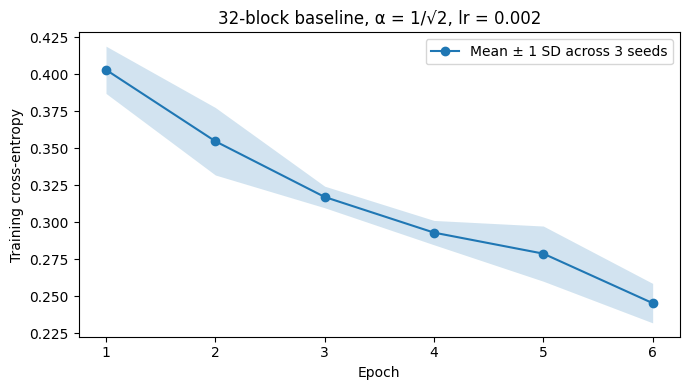

In [15]:
final_runs = load_results(
    tag="baseline_final_v2",
    depth=C.DEPTH_MAIN,
    width=C.WIDTH,
    alpha=C.ALPHA_BASELINE,
    lr=0.002,
    epochs=C.EPOCHS,
)
final_runs.sort(key=lambda run: run["seed"])

assert [run["seed"] for run in final_runs] == list(C.FINAL_SEEDS)
assert all(
    not run["diverged"] and len(run["train_loss"]) == C.EPOCHS
    for run in final_runs
)

print("Seed   Final train loss   Test accuracy")
for run in final_runs:
    print(f"{run['seed']:>4}   {run['final_train_loss']:>16.4f}   "
          f"{run['test_acc']:>13.2%}")

losses = np.array([run["final_train_loss"] for run in final_runs])
print(f"\nFinal train loss (mean ± SD): {losses.mean():.4f} ± {losses.std(ddof=1):.4f}")

epochs = np.arange(1, C.EPOCHS + 1)
curves = [run["train_loss"] for run in final_runs]

fig, ax = plt.subplots(figsize=(7, 4))
plot_mean_sd(ax, epochs, curves, label="Mean ± 1 SD across 3 seeds", marker="o")
ax.set(xlabel="Epoch", ylabel="Training cross-entropy",
       title="32-block baseline, α = 1/√2, lr = 0.002", xticks=epochs)
ax.legend()
fig.tight_layout()
plt.show()

## 7. Decisions carried into NB2

The six-epoch baseline provides the evidence for choosing the main training budget and calculating the usable-learning-rate threshold. The range check is still pending. Once it is complete, the group will freeze `hypotheses.md` and record its commit hash in NB2 §0.

### 1. Has the baseline training loss flattened by epoch 6?

We classify the curve as flat if the decrease in mean training loss from epoch 4 to epoch 6 accounts for less than 5% of the total decrease from epoch 1 to epoch 6.

Across the three final seeds (1, 2 and 3), mean training loss was **0.4029** at epoch 1, **0.2929** at epoch 4 and **0.2453** at epoch 6. Using the unrounded values, the final two epochs accounted for **30.2%** of the total decrease. This exceeds the 5% threshold, so the baseline was still improving at epoch 6. Under the agreed rule, the main sweep will use **12 epochs**.

### 2. What is the usable-learning-rate threshold?

We define `τ = 1.25 × L_base`, where `L_base` is the final training loss for the seed-0 baseline at the selected learning rate. A learning rate is usable if the run completes without divergence and its final training loss is at most `τ`.

For the **six-epoch baseline** with 32 blocks, `α = 1/√2`, `lr = 0.002` and seed 0, `L_base = 0.252905`. Applying the rule to the unrounded loss gives **τ = 0.316131**. This value will be recorded with its six-epoch training budget in `hypotheses.md` when the protocol is frozen.

### 3. Are α = 0.5 and α = 0.9 distinguishable at 32 blocks?

**Pending the range-check runs.** The range check compares `α = 0.5` and `α = 0.9` at 32 blocks using two or three learning rates. We will compare the mean training losses across seeds at the early epoch (`C.EARLY_EPOCH`) and at the range check’s final epoch (`C.EPOCHS`). The conditions are distinguishable if the 95% t interval for their difference excludes zero at either epoch. Otherwise, the group will review whether 32 blocks gives sufficient separation before freezing the design.

This check establishes whether the experiment can detect a difference over the chosen range. The main sweep supplies the evidence for evaluating the hypotheses.

### Scope of the signal-scale checks

Sections 2 and 4 show how closely the initial signal scales match across conditions. Calibration aligns the forward second moment on the calibration batch, and the backward-scale measurements show how much variation remains at initialisation. These checks support a comparison of training behaviour across skip weights under comparable initial signal scales.

### 3a. Range check protocol (C)

**What runs.** 32 blocks, `α ∈ {0.5, 0.9}`, learning rates `(1e-3, 3e-3, 1e-2)`, seeds `(0, 1, 2)`,
`RANGE_EPOCHS` epochs: 18 runs, all tagged `rangecheck` so none of them can leak into a final mean.
§7.1 moved the main sweep to 12 epochs, so the range check runs at 12 epochs and is read at epochs
1, 6 and 12; whichever budget is finally frozen, the answer is already measured.

**Why three seeds and not the seed-0 runs in the plan.** The rule in §7.3 is a 95% t interval on the
difference of means, and an interval needs a spread. With one seed per cell there is nothing to put
an interval on, and the check would answer "not distinguishable" by construction. Three seeds per
cell give four degrees of freedom on the difference for 18 short runs.

**How it is read.** For each α take the learning rate with the lowest mean final loss over seeds;
that is the fair comparison between the two conditions. A learning rate that diverges for a seed is
unusable and is listed separately instead of being averaged in. The two conditions count as
distinguishable at an epoch when the 95% t interval for the difference of their means excludes zero,
which is the rule already written into §7.3. If no epoch separates them, the note to the group is
that 32 blocks does not resolve this effect at this seed count, and the choice between a deeper
network, a longer budget and more seeds is taken in the meeting before `hypotheses.md` is frozen.

This stays a measuring-range check. Nothing here is evidence for H0–H3, and no number from this
section goes into the paper as a result.

In [ ]:
# ---- Range check (C): can 32 blocks separate alpha = 0.5 from alpha = 0.9 at all? ----
# Measuring range only, not evidence for any hypothesis (see §7.3).

RANGE_ALPHAS = (0.5, 0.9)
RANGE_LRS = (1e-3, 3e-3, 1e-2)
RANGE_SEEDS = (0, 1, 2)
RANGE_EPOCHS = C.EPOCHS_SENSITIVITY   # 12 after the §7.1 decision; keep equal to the frozen budget
RANGE_REPORT_EPOCHS = (C.EARLY_EPOCH, C.EPOCHS, RANGE_EPOCHS)
RANGE_TAG = "rangecheck"


def _t_crit(level, df):
    """Two-sided Student-t critical value at `level` with `df` degrees of freedom.

    Table up to 30 degrees of freedom, where the seed counts of this project live, and a
    Cornish-Fisher correction above that. Temporary: D is adding a shared interval helper to
    utils.py, and this local version should be replaced by it once it lands.
    """
    import statistics

    z = statistics.NormalDist().inv_cdf(1 - (1 - level) / 2)
    if level == 0.95 and 1 <= round(df) <= 30:
        return {1: 12.706, 2: 4.303, 3: 3.182, 4: 2.776, 5: 2.571,
                6: 2.447, 7: 2.365, 8: 2.306, 9: 2.262, 10: 2.228, 11: 2.201,
                12: 2.179, 13: 2.160, 14: 2.145, 15: 2.131, 16: 2.120, 17: 2.110,
                18: 2.101, 19: 2.093, 20: 2.086, 21: 2.080, 22: 2.074, 23: 2.069,
                24: 2.064, 25: 2.060, 26: 2.056, 27: 2.052, 28: 2.048, 29: 2.045,
                30: 2.042}[round(df)]
    if not df > 0:
        return float("inf")
    return z + (z ** 3 + z) / (4 * df)


def _diff_interval(xs, ys, level=0.95):
    """Welch interval for mean(ys) - mean(xs). Returns gap, standard error, df and the bounds.

    Welch rather than pooled, because the two conditions are not assumed to have the same seed
    spread. Needs at least two seeds on each side; with one seed there is no spread to use.
    """
    import math
    import statistics

    xs = [float(v) for v in xs]
    ys = [float(v) for v in ys]
    nx, ny = len(xs), len(ys)
    if nx < 2 or ny < 2:
        raise ValueError("the range check needs at least 2 seeds per condition, got "
                         f"{nx} and {ny}")
    gap = statistics.fmean(ys) - statistics.fmean(xs)
    vx, vy = statistics.variance(xs) / nx, statistics.variance(ys) / ny
    se = math.sqrt(vx + vy)
    if se == 0.0:
        return dict(gap=gap, se=0.0, df=float(nx + ny - 2), half=0.0, lo=gap, hi=gap)
    df = (vx + vy) ** 2 / (vx ** 2 / (nx - 1) + vy ** 2 / (ny - 1))
    half = _t_crit(level, df) * se
    return dict(gap=gap, se=se, df=df, half=half, lo=gap - half, hi=gap + half)


def range_check(records, alphas=RANGE_ALPHAS, depth=C.DEPTH_MAIN, width=C.WIDTH,
                epochs=RANGE_EPOCHS, report_epochs=RANGE_REPORT_EPOCHS,
                tag=RANGE_TAG, lrs=RANGE_LRS, seeds=RANGE_SEEDS, level=0.95):
    """Summarise the range check from saved results. Pure: no training, no plotting, no globals.

    Keeps only the runs that belong to this check, picks the learning rate with the lowest mean
    final loss for each alpha, and reports the difference between the two alphas at every report
    epoch with a t interval. The §7.3 rule decides: distinguishable when the interval excludes 0.
    """
    import statistics

    alphas = sorted(float(a) for a in alphas)
    if len(alphas) != 2:
        raise ValueError("the range check compares exactly two alphas")
    lrs = [float(v) for v in lrs]
    seeds = [int(v) for v in seeds]

    runs = {}
    for record in records:
        if (record.get("depth") != depth
                or int(record.get("width", width)) != width
                or record.get("epochs") != epochs
                or record.get("_meta", {}).get("tag", "") != tag
                or min(abs(float(record["alpha"]) - a) for a in alphas) > 1e-9
                or min(abs(float(record["lr"]) - v) for v in lrs) > 1e-12
                or int(record["seed"]) not in seeds):
            continue
        key = (min(alphas, key=lambda a: abs(a - float(record["alpha"]))),
               float(record["lr"]), int(record["seed"]))
        if key in runs:
            raise ValueError(f"duplicate range-check run: alpha={key[0]}, "
                             f"lr={key[1]}, seed={key[2]}")
        runs[key] = record
    if not runs:
        raise ValueError("no range-check runs matched; run the sweep cell above first")

    finished = {}       # (alpha, lr) -> {seed: per-epoch loss curve}
    unfinished = []     # diverged, or stopped before the budget
    for (alpha, lr, seed), record in runs.items():
        curve = [float(v) for v in (record.get("train_loss") or [])]
        if record.get("diverged") or len(curve) < epochs:
            unfinished.append(dict(alpha=alpha, lr=lr, seed=seed))
            continue
        finished.setdefault((alpha, lr), {})[seed] = curve

    chosen = {}
    for alpha in alphas:
        best = None
        for lr in lrs:
            curves = finished.get((alpha, lr), {})
            if len(curves) < 2:
                continue
            mean_final = statistics.fmean(c[epochs - 1] for c in curves.values())
            if best is None or mean_final < best[0]:
                best = (mean_final, lr, curves)
        if best is None:
            raise ValueError(f"alpha={alpha}: no learning rate has two finished seeds")
        chosen[alpha] = dict(lr=best[1], n=len(best[2]), mean_final=best[0], curves=best[2])

    rows = []
    for epoch in report_epochs:
        i = int(epoch) - 1
        if not 0 <= i < epochs:
            continue
        series = {a: [c[i] for c in chosen[a]["curves"].values()] for a in alphas}
        bounds = _diff_interval(series[alphas[0]], series[alphas[1]], level=level)
        rows.append(dict(epoch=int(epoch), alpha_lo=alphas[0], alpha_hi=alphas[1],
                         n={a: len(v) for a, v in series.items()},
                         mean={a: statistics.fmean(v) for a, v in series.items()},
                         sd={a: statistics.stdev(v) for a, v in series.items()},
                         **bounds,
                         excludes_zero=bool(bounds["lo"] > 0.0 or bounds["hi"] < 0.0)))

    separating = [row["epoch"] for row in rows if row["excludes_zero"]]
    return dict(level=level, epochs=epochs, alphas=alphas, chosen=chosen, rows=rows,
                unfinished=unfinished, separating_epochs=separating,
                verdict=("distinguishable at epoch " + ", ".join(str(e) for e in separating)
                         if separating else "not distinguishable at any reported epoch"))

In [ ]:
if not QUICK:
    planned = len(RANGE_ALPHAS) * len(RANGE_LRS) * len(RANGE_SEEDS)
    print(f"Range check: {planned} runs of {RANGE_EPOCHS} epochs, tag '{RANGE_TAG}'")
    for alpha in RANGE_ALPHAS:
        for lr in RANGE_LRS:
            for seed in RANGE_SEEDS:
                if result_exists(depth=C.DEPTH_MAIN, alpha=alpha, lr=lr, seed=seed,
                                 epochs=RANGE_EPOCHS, tag=RANGE_TAG):
                    continue
                record = train_one_run(depth=C.DEPTH_MAIN, alpha=alpha, lr=lr, seed=seed,
                                       epochs=RANGE_EPOCHS, save=True, tag=RANGE_TAG)
                if record["diverged"]:
                    outcome = "diverged"
                else:
                    outcome = f"final loss {record['final_train_loss']:.4f}"
                print(f"  alpha={alpha:.4f} lr={lr:g} seed={seed}: {outcome} "
                      f"({record['seconds']:.0f} s)", flush=True)

In [ ]:
range_records = load_results(tag=RANGE_TAG, depth=C.DEPTH_MAIN, width=C.WIDTH,
                             epochs=RANGE_EPOCHS)
planned = len(RANGE_ALPHAS) * len(RANGE_LRS) * len(RANGE_SEEDS)

if not range_records:
    print(f"Range check: no saved runs yet. It needs {planned} runs of {RANGE_EPOCHS} epochs "
          f"(tag '{RANGE_TAG}'); run the cell above with QUICK = False.")
else:
    checked = range_check(range_records)
    print(f"Range check · {C.DEPTH_MAIN} blocks · {len(range_records)} saved runs · "
          f"{checked['level']:.0%} t intervals\n")
    print("Learning rate used for each alpha (lowest mean final loss over seeds):")
    for alpha, info in checked["chosen"].items():
        print(f"  alpha={alpha:<6.4f} lr={info['lr']:<7g} seeds={info['n']}  "
              f"mean final loss={info['mean_final']:.4f}")
    if checked["unfinished"]:
        print(f"\nUnusable runs, not averaged in: {len(checked['unfinished'])}")
        for run in checked["unfinished"]:
            print(f"  alpha={run['alpha']} lr={run['lr']:g} seed={run['seed']}")

    lo, hi = checked["alphas"]
    print(f"\n{'epoch':>5}  {'alpha=%.2f' % lo:>20}  {'alpha=%.2f' % hi:>20}  "
          f"{'difference':>10}  {'95% interval':>23}  distinguishable")
    for row in checked["rows"]:
        left = "%+.4f ± %.3f" % (row["mean"][lo], row["sd"][lo])
        right = "%+.4f ± %.3f" % (row["mean"][hi], row["sd"][hi])
        interval = "%+.4f to %+.4f" % (row["lo"], row["hi"])
        flag = "yes" if row["excludes_zero"] else "no"
        print(f"{row['epoch']:>5}  {left:>20}  {right:>20}  "
              f"{row['gap']:>+10.4f}  {interval:>23}  {flag:>15}")

    print(f"\nVerdict: {checked['verdict']}.")
    if checked["separating_epochs"]:
        print("The measuring range is wide enough to separate the two conditions, so the main "
              "sweep can be frozen as planned. Nothing in this section is evidence for H0-H3.")
    else:
        print("32 blocks does not resolve these two conditions at this seed count, so the "
              "measuring range is too narrow. Take it to the meeting before hypotheses.md is "
              "frozen: the options are a deeper network, a longer budget or more seeds.")

In [16]:
print(f"Total runtime: {time.time() - T0:.0f} s  (QUICK = {QUICK}; must stay under 300 s when QUICK)")

Total runtime: 1759 s  (QUICK = False; must stay under 300 s when QUICK)


In [17]:
mean_curve = np.mean([run["train_loss"] for run in final_runs], axis=0)
epoch_1, epoch_4, epoch_6 = mean_curve[[0, 3, 5]]

late_drop_fraction = (epoch_4 - epoch_6) / (epoch_1 - epoch_6)

print(f"Mean training loss at epoch 1: {epoch_1:.4f}")
print(f"Mean training loss at epoch 4: {epoch_4:.4f}")
print(f"Mean training loss at epoch 6: {epoch_6:.4f}")
print(f"Fraction of total drop occurring from epoch 4 to 6: {late_drop_fraction:.1%}")
print(f"Flat under the 5% rule: {late_drop_fraction < 0.05}")

Mean training loss at epoch 1: 0.4029
Mean training loss at epoch 4: 0.2929
Mean training loss at epoch 6: 0.2453
Fraction of total drop occurring from epoch 4 to 6: 30.2%
Flat under the 5% rule: False


In [18]:
threshold_runs = load_results(
    tag="baseline_tune_v2",
    depth=C.DEPTH_MAIN,
    width=C.WIDTH,
    alpha=C.ALPHA_BASELINE,
    lr=0.002,
    seed=C.TUNE_SEED,
    epochs=6,
)

assert len(threshold_runs) == 1
baseline_run = threshold_runs[0]
assert not baseline_run["diverged"]

baseline_loss = baseline_run["final_train_loss"]
tau = 1.25 * baseline_loss

print(f"6-epoch baseline loss (seed 0): {baseline_loss:.6f}")
print(f"6-epoch usable-LR threshold: {tau:.6f}")

6-epoch baseline loss (seed 0): 0.252905
6-epoch usable-LR threshold: 0.316131
